In [1]:
#import dependencies: https://github.com/tensorflow/datasets/blob/master/tensorflow_datasets/datasets/stanford_dogs/stanford_dogs_dataset_builder.py
import collections
import os
import re
import xml.etree.ElementTree as ET
import tensorflow as tf
from tensorflow import keras
import tensorflow_datasets.public_api as tfds 
from tensorflow.keras.preprocessing.image import ImageDataGenerator

#to check 
print ("done importing")

/Users/selinacheah/miniforge3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


done importing


In [2]:
os.getcwd()

'/Users/selinacheah/tensorflow-capstone'

In [3]:
#load dataset
#dataset is downloaded from http://vision.stanford.edu/aditya86/ImageNetDogs/main.html
#make sure dataset is in the same directory!
import tarfile 
file_list = os.listdir('.')
file_list

['annotation.tar',
 '.DS_Store',
 'inceptionV3_model_featureExtraction.h5',
 'file_list.mat',
 'lists.tar',
 'test_data.mat',
 'inceptionV3_model_fineTuning.h5',
 'history_featureExtraction.npy',
 'images.tar',
 'Annotation',
 'train_data.mat',
 'Capstone.ipynb',
 'env',
 'test_list.mat',
 'history_featureExtraction_2.npy',
 'train_list.mat',
 '.ipynb_checkpoints',
 '23-24_CE301_cheah_chi_y',
 'WoofAmI_Training.ipynb',
 'WoofAmI.ipynb',
 'WoofAmI-Evaluation.ipynb']

In [4]:
#extract tar files 
for fname in file_list:
    if fname.endswith(".tar"):
        tar = tarfile.open(fname, "r:")
        tar.extractall()
        tar.close

In [5]:
#to check .tar files are extracted
os.listdir(".")

['annotation.tar',
 '.DS_Store',
 'inceptionV3_model_featureExtraction.h5',
 'file_list.mat',
 'lists.tar',
 'Images',
 'test_data.mat',
 'inceptionV3_model_fineTuning.h5',
 'history_featureExtraction.npy',
 'images.tar',
 'Annotation',
 'train_data.mat',
 'Capstone.ipynb',
 'env',
 'test_list.mat',
 'history_featureExtraction_2.npy',
 'train_list.mat',
 '.ipynb_checkpoints',
 '23-24_CE301_cheah_chi_y',
 'WoofAmI_Training.ipynb',
 'WoofAmI.ipynb',
 'WoofAmI-Evaluation.ipynb']

In [6]:
#import dependencies for training
import numpy as np
from matplotlib import pyplot as plt
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential 
import pathlib 
import shutil

print("imported")

imported


In [7]:
dataset_dir = 'Images'
os.listdir(dataset_dir)

['n02097658-silky_terrier',
 'n02092002-Scottish_deerhound',
 'n02099849-Chesapeake_Bay_retriever',
 'n02091244-Ibizan_hound',
 'n02095314-wire-haired_fox_terrier',
 'n02091831-Saluki',
 'n02102318-cocker_spaniel',
 'n02104365-schipperke',
 'n02090622-borzoi',
 'n02113023-Pembroke',
 'n02105505-komondor',
 'n02093256-Staffordshire_bullterrier',
 'n02113799-standard_poodle',
 'n02109961-Eskimo_dog',
 'n02089973-English_foxhound',
 'n02099601-golden_retriever',
 'n02095889-Sealyham_terrier',
 'n02085782-Japanese_spaniel',
 'n02097047-miniature_schnauzer',
 'n02110063-malamute',
 'n02105162-malinois',
 'n02086079-Pekinese',
 'n02097130-giant_schnauzer',
 'n02113978-Mexican_hairless',
 'n02107142-Doberman',
 'n02097209-standard_schnauzer',
 'n02115913-dhole',
 'n02106662-German_shepherd',
 'n02106382-Bouvier_des_Flandres',
 'n02110185-Siberian_husky',
 'n02094258-Norwich_terrier',
 'n02093991-Irish_terrier',
 'n02094114-Norfolk_terrier',
 'n02109525-Saint_Bernard',
 'n02093754-Border_terri

In [8]:
data = tf.keras.utils.image_dataset_from_directory('Images')

Found 20580 files belonging to 120 classes.


In [9]:
train_dir = os.path.join(dataset_dir, 'train')
val_dir = os.path.join(dataset_dir, 'val')
test_dir = os.path.join(dataset_dir, 'test')


In [10]:
# function to split and move images 
def split_and_move_images(images, train_target, val_target, test_target):
    np.random.shuffle(images)
    num_train = int(0.7 * len(images))
    num_val = int(0.2 * len(images))

    for i, img in enumerate(images):
        if i < num_train:
            shutil.move(img, train_target)
        elif i < num_train + num_val:
            shutil.move(img, val_target)
        else:
            shutil.move(img, test_target)


In [11]:
# Process each breed subdirectory
for breed in os.listdir(dataset_dir):
    breed_dir = os.path.join(dataset_dir, breed)
    if os.path.isdir(breed_dir):
        # Create breed subdirectories in train, val, and test
        train_breed_dir = os.path.join(train_dir, breed)
        val_breed_dir = os.path.join(val_dir, breed)
        test_breed_dir = os.path.join(test_dir, breed)
        os.makedirs(train_breed_dir, exist_ok=True)
        os.makedirs(val_breed_dir, exist_ok=True)
        os.makedirs(test_breed_dir, exist_ok=True)

        # Get all image files
        images = [os.path.join(breed_dir, f) for f in os.listdir(breed_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        # Split and move images
        split_and_move_images(images, train_breed_dir, val_breed_dir, test_breed_dir)
        

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

#data augmentation for training set
train_gen = ImageDataGenerator(
    rescale=1.0/255.0, 
    width_shift_range=0.2, 
    height_shift_range=0.2, 
    horizontal_flip=True)

train_set = train_gen.flow_from_directory(
    train_dir, 
    seed=10, 
    class_mode='sparse', 
    batch_size=32, 
    shuffle=True, 
    target_size=(224, 224))


Found 14355 images belonging to 120 classes.


In [18]:
#avoid augmentation in validation to represent real-world scenarios
val_gen = ImageDataGenerator(rescale=1.0/255.0)

val_set = val_gen.flow_from_directory(
    val_dir, 
    seed=10, 
    class_mode='sparse', 
    batch_size=32, 
    shuffle=True, 
    target_size=(224, 224))


Found 4072 images belonging to 120 classes.


In [19]:
test_gen = ImageDataGenerator(rescale=1.0/255.0)

test_set = test_gen.flow_from_directory(
    test_dir, 
    seed=10, 
    class_mode='sparse', 
    batch_size=32, 
    shuffle=True, 
    target_size=(224, 224))


Found 2153 images belonging to 120 classes.


In [27]:
class_names = {y: x for x, y in val_set.class_indices.items()}
class_names

{0: 'n02085620-Chihuahua',
 1: 'n02085782-Japanese_spaniel',
 2: 'n02085936-Maltese_dog',
 3: 'n02086079-Pekinese',
 4: 'n02086240-Shih-Tzu',
 5: 'n02086646-Blenheim_spaniel',
 6: 'n02086910-papillon',
 7: 'n02087046-toy_terrier',
 8: 'n02087394-Rhodesian_ridgeback',
 9: 'n02088094-Afghan_hound',
 10: 'n02088238-basset',
 11: 'n02088364-beagle',
 12: 'n02088466-bloodhound',
 13: 'n02088632-bluetick',
 14: 'n02089078-black-and-tan_coonhound',
 15: 'n02089867-Walker_hound',
 16: 'n02089973-English_foxhound',
 17: 'n02090379-redbone',
 18: 'n02090622-borzoi',
 19: 'n02090721-Irish_wolfhound',
 20: 'n02091032-Italian_greyhound',
 21: 'n02091134-whippet',
 22: 'n02091244-Ibizan_hound',
 23: 'n02091467-Norwegian_elkhound',
 24: 'n02091635-otterhound',
 25: 'n02091831-Saluki',
 26: 'n02092002-Scottish_deerhound',
 27: 'n02092339-Weimaraner',
 28: 'n02093256-Staffordshire_bullterrier',
 29: 'n02093428-American_Staffordshire_terrier',
 30: 'n02093647-Bedlington_terrier',
 31: 'n02093754-Border_

In [28]:
num_classification_categories = len(class_names)
print('Number of classes=%d' % num_classification_categories)

Number of classes=120


In [29]:
# import libraries and pre-trained model  
from tensorflow.keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, InputLayer
from keras import layers, models
from keras.models import Sequential
from keras import optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.layers import Conv2D, MaxPooling2D,GlobalAveragePooling2D, Input
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.models import Sequential, Model
from sklearn import metrics
from tqdm import tqdm
from keras.applications.inception_v3 import InceptionV3


In [30]:
#initialise the base model 
base_model = InceptionV3(#input_shape=(224,224,3),
                          include_top = True,
                          weights = 'imagenet')

base_model.summary()

Model: "inception_v3"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 299, 299, 3)]        0         []                            
                                                                                                  
 conv2d_94 (Conv2D)          (None, 149, 149, 32)         864       ['input_2[0][0]']             
                                                                                                  
 batch_normalization_94 (Ba  (None, 149, 149, 32)         96        ['conv2d_94[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activation_94 (Activation)  (None, 149, 149, 32)         0         ['batch_normalizati

In [31]:
# Unfreeze all layers initially
for layer in base_model.layers:
    layer.trainable = True

# Freeze all layers except the last two -retain pre-trained knowledge
# allows model to adjust its higher level features that is closer to output layer 
for layer in base_model.layers[:-2]:
    layer.trainable = False

In [32]:
#adding fully connected layers onto model 
x = Flatten()(base_model.output) 


In [33]:
# add dropout and L2 regularization 
from keras.regularizers import l2

x = Dropout(0.5)(x)
prediction = Dense(
    num_classification_categories, 
    activation='softmax', 
    kernel_regularizer=l2(0.001)  # L2 regularization
)(x)


In [34]:
#visualise
model = models.Model(inputs=base_model.input, outputs=prediction)
model.summary()


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 299, 299, 3)]        0         []                            
                                                                                                  
 conv2d_94 (Conv2D)          (None, 149, 149, 32)         864       ['input_2[0][0]']             
                                                                                                  
 batch_normalization_94 (Ba  (None, 149, 149, 32)         96        ['conv2d_94[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activation_94 (Activation)  (None, 149, 149, 32)         0         ['batch_normalization_94[0

In [35]:
#compile first phase
from tensorflow.keras.optimizers import Adam 
from tensorflow.keras.metrics import Precision, Recall
import scipy

model.compile(loss=keras.losses.SparseCategoricalCrossentropy(), 
                 optimizer=keras.optimizers.legacy.Adam(), #'tf.keras.optimizers.Adam` runs slowly on M1
                 metrics=['accuracy'])


In [36]:
#setting up EarlyStopping callback
early_stopping = EarlyStopping(
    monitor = 'val_loss',
    min_delta = 0.001, 
    patience = 10,
    verbose = 1,
    restore_best_weights = True
)


In [37]:
my_callbacks = [
    ModelCheckpoint(filepath='inceptionV3_model_featureExtraction.h5', save_best_only=True),
    early_stopping 
]


In [38]:
#fitting

history = model.fit(
    train_set,
    epochs=3,
    validation_data=val_set,
    callbacks=my_callbacks #earlystopping
)
np.save('history_featureExtraction.npy', [history.history['accuracy'], history.history['val_accuracy']]) 

Epoch 1/3
449/449 [==============================] - ETA: 0s - loss: 4.7197 - accuracy: 0.1573

/Users/selinacheah/miniforge3/lib/python3.10/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


449/449 [==============================] - 354s 784ms/step - loss: 4.7197 - accuracy: 0.1573 - val_loss: 4.6295 - val_accuracy: 0.3352
Epoch 2/3
449/449 [==============================] - 358s 798ms/step - loss: 4.5888 - accuracy: 0.1641 - val_loss: 4.5241 - val_accuracy: 0.3224
Epoch 3/3
449/449 [==============================] - 356s 792ms/step - loss: 4.4990 - accuracy: 0.1598 - val_loss: 4.4319 - val_accuracy: 0.3298


In [39]:
#function to gradually unfreeze layers 
def unfreeze_model(model, layers_to_unfreeze):
    #freeze all layers first 
    for layer in model.layers:
        layer.trainable = False

    #unfreeze some layers 
    for layer in model.layers[-layers_to_unfreeze:]:
        layer.trainable = True

    #compile the model after unfreezing 
    model.compile(loss=keras.losses.SparseCategoricalCrossentropy(), 
                  optimizer=keras.optimizers.legacy.Adam(),
                  metrics=['accuracy'])
    

In [40]:
#Phase 2- unfreeze more layers
unfreeze_model(model, 10)
history = model.fit(
    train_set,
    epochs=2,
    validation_data=val_set,
    callbacks=my_callbacks #earlystopping
)
np.save('history_featureExtraction.npy', [history.history['accuracy'], history.history['val_accuracy']]) 


Epoch 1/2
449/449 [==============================] - 372s 822ms/step - loss: 4.4268 - accuracy: 0.1650 - val_loss: 4.3606 - val_accuracy: 0.3224
Epoch 2/2
449/449 [==============================] - 359s 800ms/step - loss: 4.3651 - accuracy: 0.1643 - val_loss: 4.2889 - val_accuracy: 0.3342


In [41]:
#fine-tuning 
# load base InceptionV3 model w/o its top layers
base_model = InceptionV3(
    include_top=False, 
    weights='imagenet', 
    input_shape=(224, 224, 3)
)


In [42]:
# freeze the base model layers 
for layer in base_model.layers:
    layer.trainable = False
    

In [43]:
# add new layers
x = layers.Flatten()(base_model.output)

x = layers.Dropout(0.5)(x) #regularization

prediction = layers.Dense(num_classification_categories, activation='softmax', kernel_regularizer=l2(0.001))(x)


In [44]:
# create new model 
model = models.Model(inputs=base_model.input, outputs = prediction)


In [45]:
# compile the model 
model.compile(optimizer=tf.keras.optimizers.legacy.Adam(), 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy']
             )


In [46]:
# Set up callbacks
early_stopping = EarlyStopping(
    monitor='val_loss', 
    min_delta=0.001, 
    patience=10, 
    verbose=1, 
    restore_best_weights=True)

my_callbacks = [ModelCheckpoint(filepath='inceptionV3_model_featureExtraction.h5', 
                                save_best_only=True), 
                early_stopping]


In [47]:
# Train the model
history = model.fit(
    train_set, 
    epochs=3, 
    validation_data=val_set, 
    callbacks=my_callbacks
)


Epoch 1/3
449/449 [==============================] - 360s 797ms/step - loss: 11.6850 - accuracy: 0.5758 - val_loss: 10.3442 - val_accuracy: 0.7220
Epoch 2/3
449/449 [==============================] - 355s 791ms/step - loss: 13.0343 - accuracy: 0.6773 - val_loss: 13.5442 - val_accuracy: 0.7245
Epoch 3/3
449/449 [==============================] - 356s 793ms/step - loss: 14.0938 - accuracy: 0.7073 - val_loss: 15.5268 - val_accuracy: 0.7262


In [48]:
# unfreeze the last few layers for fine-tuning 
num_layers_to_unfreeze = 10
for layer in base_model.layers [-num_layers_to_unfreeze:]:
    layer.trainable = True
    

In [49]:
# compile model with a smaller learning rate 
model.compile(optimizer=keras.optimizers.legacy.Adam(learning_rate=1e-5), 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy']
             )


In [50]:
# train the model
history_fine = model.fit(train_set, 
                         epochs=5, 
                         validation_data=val_set, 
                         callbacks=my_callbacks
                        )


Epoch 1/5
449/449 [==============================] - 360s 796ms/step - loss: 12.4574 - accuracy: 0.7546 - val_loss: 12.3328 - val_accuracy: 0.7753
Epoch 2/5
449/449 [==============================] - 358s 798ms/step - loss: 10.6666 - accuracy: 0.7821 - val_loss: 11.6301 - val_accuracy: 0.7849
Epoch 3/5
449/449 [==============================] - 359s 799ms/step - loss: 9.8889 - accuracy: 0.8008 - val_loss: 11.3611 - val_accuracy: 0.7888
Epoch 4/5
449/449 [==============================] - 359s 799ms/step - loss: 9.7703 - accuracy: 0.8008 - val_loss: 11.1981 - val_accuracy: 0.7903
Epoch 5/5
449/449 [==============================] - 358s 796ms/step - loss: 9.2168 - accuracy: 0.8093 - val_loss: 11.0412 - val_accuracy: 0.7930


In [51]:
# evaluate test set
test_loss, test_accuracy = model.evaluate(test_set)

print("results")
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

68/68 [==============================] - 40s 584ms/step - loss: 11.1489 - accuracy: 0.7784
results
Test Loss: 11.148859977722168
Test Accuracy: 0.7784487009048462


In [52]:
# save weights 
model.save_weights('inceptionV3_model_weights.h5')


In [59]:
import random

# randomly select a batch from the test_set 
batch = next(iter(test_set))

# select a random image from the batch
image_index = random.randint(0, batch[0].shape[0] - 1)


In [60]:
# get image and its true label 
selected_image = batch[0][image_index]

true_label_index = batch[1][image_index]

true_label = list(test_set.class_indices.keys())[list
(test_set.class_indices.values())
.index(true_label_index)]


In [61]:
# predict the class 
predictions = model.predict(np.expand_dims(selected_image, axis=0))

predicted_class = np.argmax(predictions, axis=1)


1/1 [==============================] - 0s 49ms/step


In [62]:
# retrieve predicted class label
predicted_label = list(test_set.class_indices.keys())[
list(test_set.class_indices.values()).index(predicted_class[0])]


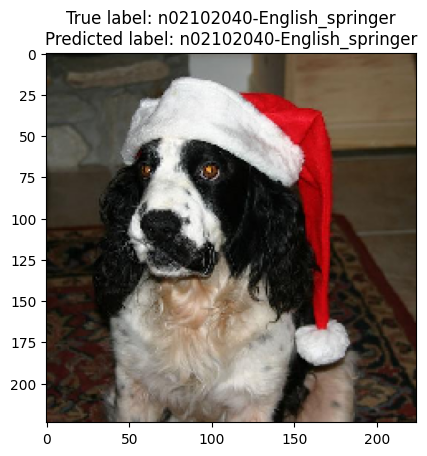

In [63]:
# visualize the image and prediction
plt.imshow(selected_image)
plt.title(f"True label: {true_label}\nPredicted label: {predicted_label}")
plt.show()


In [64]:
# testing more images 
# function to predict and plot an image
def predict_and_plot(image, true_label_index, subplot):
    
    # predict the class
    predictions = model.predict(np.expand_dims(image, axis=0))
    predicted_class = np.argmax(predictions, axis=1)

    # retrieve true and predicted class labels
    true_label = list(test_set.class_indices.keys())[list(test_set.class_indices.values()).index(true_label_index)]
    predicted_label = list(test_set.class_indices.keys())[list(test_set.class_indices.values()).index(predicted_class[0])]

    # plot the image and labels
    plt.subplot(subplot)
    plt.imshow(image)
    plt.title(f"True: {true_label}\nPredicted: {predicted_label}")
    plt.axis('off')
    

In [65]:
# randomly select a batch from the test set 
batch = next(iter(test_set))


1/1 [==============================] - 0s 38ms/step


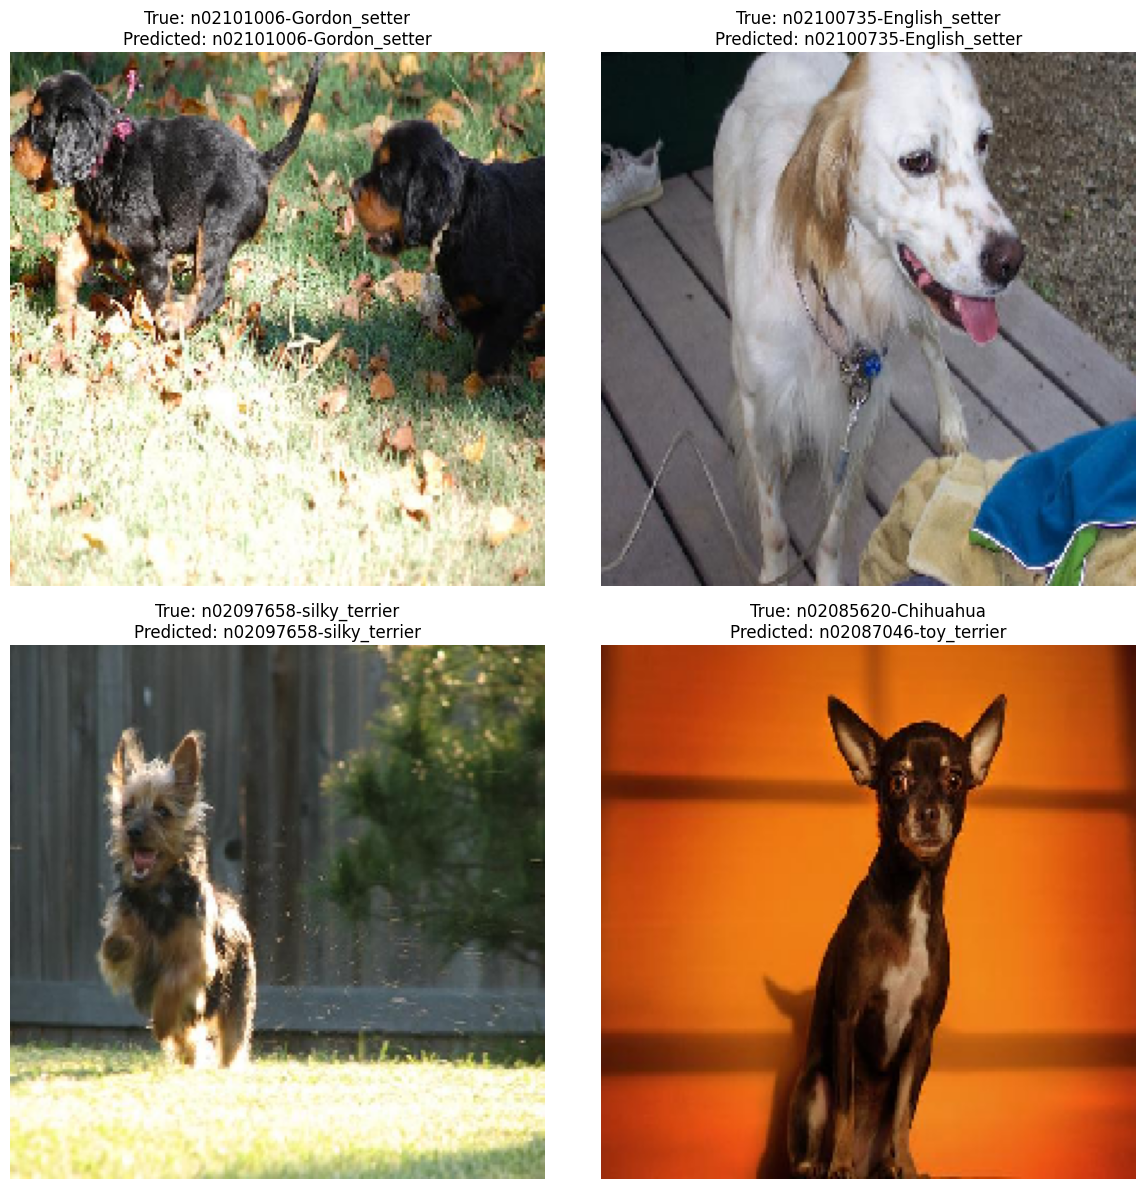

In [67]:
# set up the plot 
plt.figure(figsize=(12, 12))

# predict and plot 4 images
for i in range(4):
    image_index = random.randint(0, batch[0].shape[0] - 1)  # Select a random image from the batch
    predict_and_plot(batch[0][image_index], batch[1][image_index], 221 + i)

plt.tight_layout()
plt.show()


In [68]:
# test with own image 
from keras.preprocessing import image
from PIL import Image

# function to load, preprocess and predict the class of an image 
def load_and_predict(image_path):
    
    # load the image
    img = Image.open(image_path)
    img = img.resize((224, 224))

    # convert the image to a numpy array and normalize it
    img_array = image.img_to_array(img) / 255.0

    # expand dimensions to fit the model input format
    img_array = np.expand_dims(img_array, axis=0)

    # predict the class
    predictions = model.predict(img_array)
    predicted_class = np.argmax(predictions, axis=1)
    predicted_label = list(test_set.class_indices.keys())[list(test_set.class_indices.values()).index(predicted_class[0])]

    # display the image and prediction
    plt.imshow(img)
    plt.title(f"Predicted: {predicted_label}")
    plt.axis('off')
    plt.show()
    

In [69]:
# path to image 
image_path = 'IMG_3189.jpg'


1/1 [==============================] - 0s 77ms/step


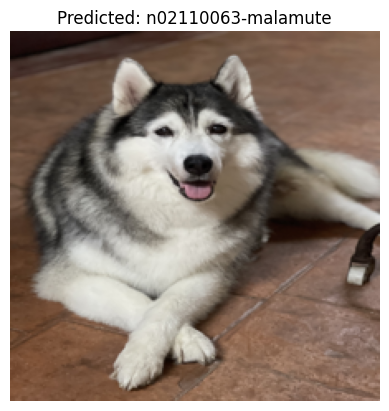

In [70]:
# predict and display
load_and_predict(image_path)


1/1 [==============================] - 0s 89ms/step


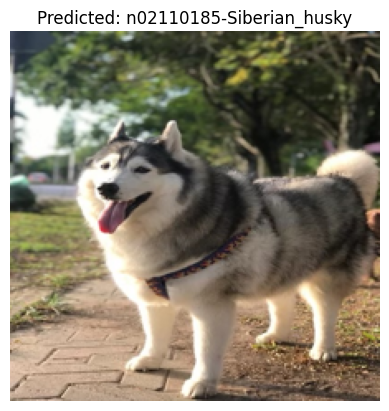

In [71]:
image_path2 ='9eb38b18-36a3-420a-ba5a-c82a6566ef42.jpeg'
load_and_predict(image_path2)

1/1 [==============================] - 0s 51ms/step


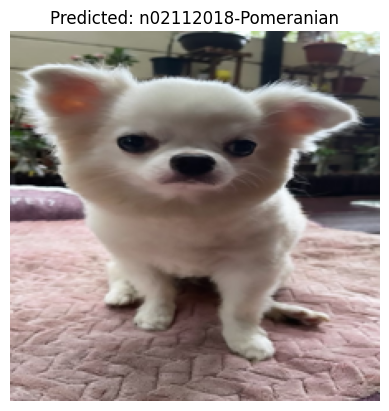

In [72]:
image_path3 = 'C4F96ECB-8DC6-4043-800B-2531BFDC05BA.jpeg'
load_and_predict(image_path3)

1/1 [==============================] - 0s 71ms/step


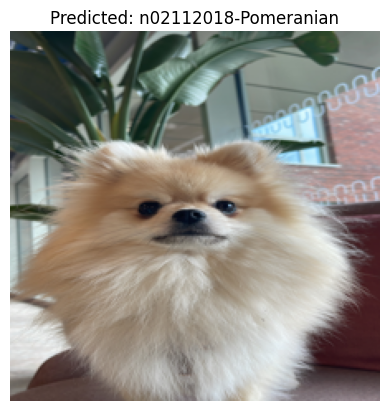

In [77]:
image_path4 = 'Indie.JPG'
load_and_predict(image_path4)